In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score as score
from sklearn.metrics import accuracy_score as accuracy
from sklearn.datasets import make_classification as mc
from sklearn.datasets import make_circles
from sklearn.datasets import make_blobs

from sklearn.linear_model import LinearRegression as LR
from sklearn.preprocessing import PolynomialFeatures as PF
from sklearn.svm import SVC
from sklearn.svm import LinearSVC
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler as SC

from collections import defaultdict

import seaborn as sns

import time

from mlxtend.plotting import plot_decision_regions

### 1. В выполненной работе добавьте замер времени обучения каждой модели.

In [ ]:
def ttime(t1):
  t2 = time.time()
  print(f'\n\nSeconds elapsed: {t2-t1}\n\n')



Seconds elapsed: 0.004587650299072266


0.37467360318911636


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


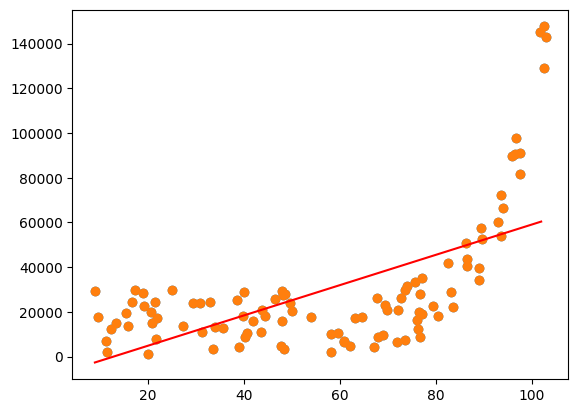

In [ ]:
data = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/gen_regression.csv",
                   index_col=0)
X = data[['x']]
y = data.y
plt.scatter(X, y)
t1 = time.time()
linear = LR().fit(X, y)
ttime(t1)
X = pd.DataFrame(X)

xx = np.arange(X.x.min(axis=0), X.x.max(axis=0))
yy = linear.predict(pd.DataFrame(xx))

plt.scatter(X.x, y)
plt.plot(xx, yy, c='r')
print(linear.score(X, y))



Seconds elapsed: 0.0018947124481201172


0.7359753787024842


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


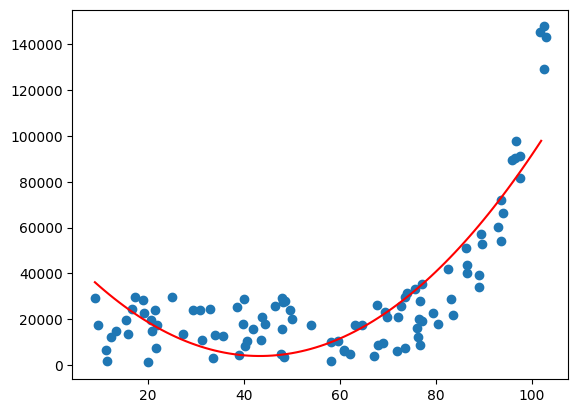

In [ ]:
data = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/gen_regression.csv",
                   index_col=0)
X = data[['x']]
y = data.y
transformation = PF(degree=2)
transformation.fit(X)
X_2 = transformation.transform(X)

t1 = time.time()
poly_2d = LR().fit(X_2, y)
ttime(t1)

xx_2d = transformation.transform(pd.DataFrame(xx))
yy_2d = poly_2d.predict(xx_2d)
plt.scatter(X.x, y)
plt.plot(xx, yy_2d, c='r')
print(poly_2d.score(X_2, y))



Seconds elapsed: 0.00609588623046875




<ipython-input-38-38dad53408a3>:13: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  np.arange(X.min()[0], X.max()[0]+0.1, 0.01),
<ipython-input-38-38dad53408a3>:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  np.arange(X.min()[1], X.max()[1]+0.1, 0.01))
/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


0.5164010825810481


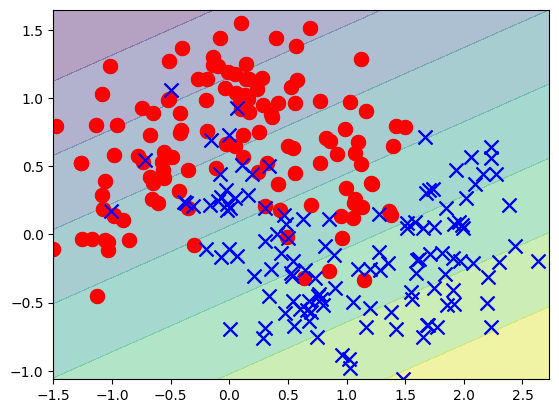

In [ ]:
data = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/gen_classification.csv",
                   index_col=0)
y = data.y
X = data.drop(["y"], axis=1)
plt.scatter(X.iloc[:, 0][y==0], X.iloc[:, 1][y==0], marker="o", c='r', s=100)
plt.scatter(X.iloc[:, 0][y==1], X.iloc[:, 1][y==1], marker="x", c='b', s=100)

t1=time.time()
logistic = LR().fit(X, y)
ttime(t1)

xx, yy = np.meshgrid(
    np.arange(X.min()[0], X.max()[0]+0.1, 0.01),
    np.arange(X.min()[1], X.max()[1]+0.1, 0.01))
XX = np.array(list(zip(xx.ravel(), yy.ravel()))).reshape((-1, 2))

Z = logistic.predict(XX).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.4)
plt.scatter(X.iloc[:, 0][y==0], X.iloc[:, 1][y==0], marker="o", c='r', s=100)
plt.scatter(X.iloc[:, 0][y==1], X.iloc[:, 1][y==1], marker="x", c='b', s=100)
print(logistic.score(X, y))



Seconds elapsed: 0.006514310836791992


0.6116981013277054


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


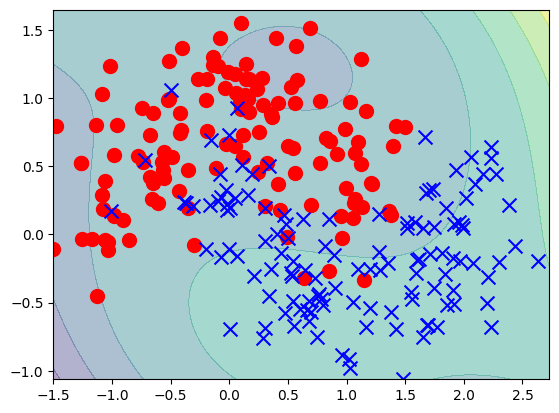

In [ ]:
data = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/gen_classification.csv",
                   index_col=0)
y = data.y
X = data.drop(["y"], axis=1)
class_transform = PF(degree=3, include_bias=False)
X_3 = class_transform.fit_transform(X)

t1=time.time()
class_3 = LR().fit(X_3, y)
ttime(t1)

Z = class_3.predict(class_transform.transform(XX)).reshape(xx.shape)
plt.contourf(xx, yy, Z, alpha=0.4)
plt.scatter(X.iloc[:, 0][y==0], X.iloc[:, 1][y==0], marker="o", c='r', s=100)
plt.scatter(X.iloc[:, 0][y==1], X.iloc[:, 1][y==1], marker="x", c='b', s=100)
print(class_3.score(X_3, y))

In [ ]:
data_kc_prices = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/kc_house_data.csv")
y_kc_prices = data_kc_prices.price
X_kc_prices = data_kc_prices.drop(["id", "date", "price"], axis=1)

t1=time.time()
reg_kc_multiple = LR().fit(X_kc_prices, y_kc_prices)
ttime(t1)

print(reg_kc_multiple.score(X_kc_prices, y_kc_prices))



Seconds elapsed: 0.08423995971679688


0.6997471890109161




Seconds elapsed: 9.130554437637329


0.8659203541563689


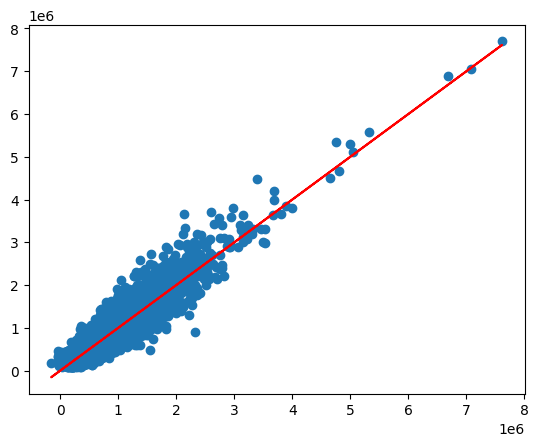

In [ ]:
data_kc_prices = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/kc_house_data.csv")
y_kc_prices = data_kc_prices.price
X_kc_prices = data_kc_prices.drop(["id", "date", "price"], axis=1)
X_3_kc_prices = (poly_features_kc_prices := PF(degree=3)).fit_transform(X_kc_prices)

t1=time.time()
reg_poly2_kc = LR().fit(X_3_kc_prices, y_kc_prices)
ttime(t1)

print(reg_poly2_kc.score(X_3_kc_prices, y_kc_prices))

y_pred_kc_prices = reg_poly2_kc.predict(X_3_kc_prices)
plt.scatter(y_pred_kc_prices, y_kc_prices)
plt.plot(y_pred_kc_prices, y_pred_kc_prices, c='r')

### 2. На датасете "gen_regression" постройте модель пятого, десятого и сотого порядков. Сравните эффективность и время обучения каждой модели.

In [ ]:
data = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/gen_regression.csv",
                   index_col=0)
x = p[['x']]
y = p['y']

deg = [5,10,100]
for i in deg:
  xl = PF(degree=i).fit_transform(x)

  t1=time.time()
  m = LR().fit(xl,y)
  ttime(t1)

  print(i,m.score(xl,y))




Seconds elapsed: 0.012034416198730469


5 0.9217478060447024


Seconds elapsed: 0.012039899826049805


10 0.9232002062571606


Seconds elapsed: 0.6438901424407959


100 0.7924620004697494


эффективность для малого порядка больше (т.к. score больше), время обучения больше при большом порядке модели

###3. То же самое проделайте с датасетом для классификации и "King county".

In [ ]:
p = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/gen_classification.csv",
                   index_col=0)
y = p[['y']]
x = p.drop('y',axis=1)

deg = [5,10,100]
for i in deg:
  xl = PF(degree=i).fit_transform(x)

  t1=time.time()
  m = LR().fit(xl,y)
  ttime(t1)

  print(i,m.score(xl,y))




Seconds elapsed: 0.003830432891845703


5 0.6755976386755245


Seconds elapsed: 0.28652167320251465


10 0.7439555827260859


Seconds elapsed: 0.8698956966400146


100 0.0766775789183749


In [ ]:
file_name='https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/DA0101EN/coursera/project/kc_house_data_NaN.csv'
p=pd.read_csv(file_name, index_col='Unnamed: 0')
p = p.dropna()

x = p.drop(['price','date','id'],axis=1)
y = p['price']

deg = [1,2,3]
for i in deg:
  xl = PF(degree=i).fit_transform(x)

  t1=time.time()
  m = LR().fit(xl,y)
  ttime(t1)

  print(i,m.score(xl,y))



Seconds elapsed: 0.014397382736206055


1 0.7001290544893117


Seconds elapsed: 0.4059329032897949


2 0.8287795266171073


Seconds elapsed: 10.887210130691528


3 0.8670089115387263


In [ ]:
p = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/kc_house_data.csv")
p = p.dropna()

x = p.drop(['price','date','id'],axis=1)
y = p['price']

deg = [1,5,100]
for i in deg:
  xl = PF(degree=i).fit_transform(x)

  t1=time.time()
  m = LR().fit(xl,y)
  ttime(t1)

  print(i,m.score(xl,y))



Seconds elapsed: 0.017667293548583984


1 0.6997471890109157


(на степени polynomialfeatures > 3 ОЗУ исчерпан и программа перестает работать)

###4. Составьте таблицу эффективности разных моделей для каждой задачи. В таблице должна быть информация о времени обучения модели и получившейся точности. Сделайте вывод о целесообразности применения разных степеней полиномов.

1 == King County


2 == Regression


3 == Classification

In [ ]:
def Compute(deg_max, x,y):
  deg = [i for i in range(1,deg_max+1)]
  out=[]
  for i in deg:
    xl = PF(degree=i).fit_transform(x)
    t1=time.time()
    m = LR().fit(xl,y)
    t2=time.time()
    out.append((m.score(xl,y),i,t2-t1))
  p = pd.DataFrame(out,columns=['score','degree','time'])
  p.index = p['degree']
  p=p.drop('degree',axis=1)
  return p
p1 = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/kc_house_data.csv")
x1 = p1.drop(['price','date','id'],axis=1)
y1 = p1[['price']]
x1 = SC().fit_transform(x1)
y1 = SC().fit_transform(y1)

p2 = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/gen_regression.csv",index_col=0)
x2 = p2[['x']]
y2 = p2['y']

p3 = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/gen_classification.csv",index_col=0)
y3 = p2[['y']]
x3 = p2.drop('y',axis=1)

l1 = Compute(3,x1,y1)
display(l1)

l2 = Compute(100,x2,y2)
display(l2)

l3 = Compute(100,x3,y3)
display(l3)

,score,time
degree,,
1,0.699759,0.133414
2,0.829488,1.479644
3,0.901342,9.384807


,score,time
degree,,
1,0.374674,0.012565
2,0.735975,0.001371
3,0.897448,0.001433
4,0.918601,0.001440
5,0.921748,0.001409
...,...,...
96,0.799352,0.002889
97,0.797600,0.002762
98,0.795868,0.002658


,score,time
degree,,
1,0.374674,0.006745
2,0.735975,0.006917
3,0.897448,0.002196
4,0.918601,0.007164
5,0.921748,0.002087
...,...,...
96,0.799352,0.107252
97,0.797600,0.010091
98,0.795868,0.006242


наилучший скор у этих моделей:

In [ ]:
display(l1.loc[l1['score'] == l1.max(axis=0).iloc[0]])
display(l2.loc[l2['score'] == l2.max(axis=0).iloc[0]])
display(l3.loc[l3['score'] == l3.max(axis=0).iloc[0]])

,score,time
degree,,
3,0.901342,9.384807


,score,time
degree,,
13,0.924829,0.00135


,score,time
degree,,
13,0.924829,0.001532


###5. Для линейной модели в задаче о продаже домов выведите коэффициенты модели и названия соответствующих атрибутов. Сделайте вывод об относительной важности атрибутов.

стандартизируем данные, чтобы удобнее было сравнивать важность атрибутов (если все атрибуты находятся в диапазоне значений [0,1], тогда их коэффициенты регрессии будут означать степень их важности)

In [ ]:
p1 = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/kc_house_data.csv")
x1 = p1.drop(['price','date','id'],axis=1)
y1 = p1[['price']]

x2 = SC().fit_transform(x1)
y2 = SC().fit_transform(y1)

m = LR().fit(x2,y2)
m.score(x2,y2)

0.6997471890109157

In [ ]:
x1.columns

Index(['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'grade', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long',
       'sqft_living15', 'sqft_lot15'],
      dtype='object')

In [ ]:
print(*zip(x1.columns,m.coef_[0,1:]),sep='\n')

('bedrooms', 0.08631288490629585)
('bathrooms', 0.22285028357495854)
('sqft_living', 0.014508839360636726)
('sqft_lot', 0.009839322202909206)
('floors', 0.13738046576818091)
('waterfront', 0.11035938617820296)
('view', 0.046769288315604535)
('condition', 0.30701965025570815)
('grade', 0.2078497208534892)
('sqft_above', 0.07356116515409376)
('sqft_basement', -0.20964094601734098)
('yr_built', 0.02167723787118352)
('yr_renovated', -0.0848817262858948)
('zipcode', 0.22749344477504532)
('lat', -0.08236939693509036)
('long', 0.04047709753618598)
('sqft_living15', -0.028458043682272)


In [ ]:
m.coef_.mean()

0.05611886064739132

самые важные для регрессии атрибуты (оцениваем по велчине их коэффициента в модели):

In [ ]:
print(*(sorted(zip(m.coef_[0,1:],x1.columns))[:-4:-1] + sorted(zip(m.coef_[0,1:],x1.columns))[:3:]),sep='\n')

(0.30701965025570815, 'condition')
(0.22749344477504532, 'zipcode')
(0.22285028357495854, 'bathrooms')
(-0.20964094601734098, 'sqft_basement')
(-0.0848817262858948, 'yr_renovated')
(-0.08236939693509036, 'lat')


###6. Попробуйте также проинтерпретировать полиномиальную модель.

In [4]:
p1 = pd.read_csv("https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML3.1%20polynomial%20features/kc_house_data.csv")
x1 = p1.drop(['price','date','id'],axis=1)
y1 = p1[['price']]

x2 = SC().fit_transform(x1)
poly = PF(degree=3)
x2 = poly.fit_transform(x2)
x2 = SC().fit_transform(x2)
y2 = SC().fit_transform(y1)

m = LR().fit(x2,y2)
m.score(x2,y2)

0.9013420277776412

In [ ]:
m.coef_.shape

(1, 1330)

In [15]:
feature_names = np.array(list(zip(poly.get_feature_names_out(input_features=x1.columns), m.coef_[0])))
d = defaultdict(list)
col = x1.columns
for i in feature_names:
  l = [attr for attr in col if attr in i[0]]
  for j in l:
    d[j].append(i[1])
l=[]
for i in d.keys():
  print(i,np.mean([abs(np.float64(k)) for k in d[i]]))
  l.append((np.mean([abs(np.float64(k)) for k in d[i]]),i))
print('\n\n')
print(*list(sorted(l)[:-4:-1]),sep='\n')

bedrooms 165912834.16290963
bathrooms 174468373.14253724
sqft_living 606317903.8258088
sqft_lot 204811229.88185784
floors 354451239.2017675
waterfront 350672974.60406744
view 197891645.0610197
condition 217247488.10900015
grade 265878637.39995134
sqft_above 836921606.5813785
sqft_basement 544647829.9917971
yr_built 250444883.34145772
yr_renovated 199473310.16141278
zipcode 144616253.00429916
lat 150660581.6773947
long 211056202.82739615
sqft_living15 288930595.54988027
sqft_lot15 189377325.0543252



(836921606.5813785, 'sqft_above')
(606317903.8258088, 'sqft_living')
(544647829.9917971, 'sqft_basement')


из этих значений мы можем сделать вывод, что в полиномиальной модели самые значимые атрибуты будут sqft_above, sqft_living, sqft_basement